# Assignment 1

Texts used:
- The Hobbit — J.R.R. Tolkien
- The Fellowship of the Ring — J.R.R. Tolkien
- Manuel Pereira — F.C. Adams

In [ ]:
import re
from collections import Counter
import matplotlib.pyplot as plt


# stop-word list
stop_words = set("the a an and or but if then of to in on for with at by from is are was were be been being it its this that these those i you he she they we me him her them my your his their our as not do does did have has had so than too very can could would should will just".split())

def get_wf(filename):
    with open(filename, 'r', encoding='utf-8', errors='replace') as f:
        text = f.read().lower()

    words = re.findall(r"[a-z]+", text)
    words = [w for w in words if w not in stop_words]
    return Counter(words), len(words)

def top15(wf):
    return wf.most_common(15)

def plot_two(wf1, wf2, name1, name2):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, wf, title in [(axes[0], wf1, name1), (axes[1], wf2, name2)]:
        data = top15(wf)[::-1]
        ax.barh([w for w, c in data], [c for w, c in data])
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

In [2]:
hobbit, hobbit_total = get_wf("the-hobbit-1.txt")
fellowship, fellowship_total = get_wf("The Fellowship of the Ring_ Bei - J.R.R. Tolkien _Worldfreebooks.com_.txt")
adams, adams_total = get_wf("pg4680.txt")

## 1. Compare word frequencies between two works of a single author

J.R.R. Tolkien: *The Hobbit* vs. *The Fellowship of the Ring*.

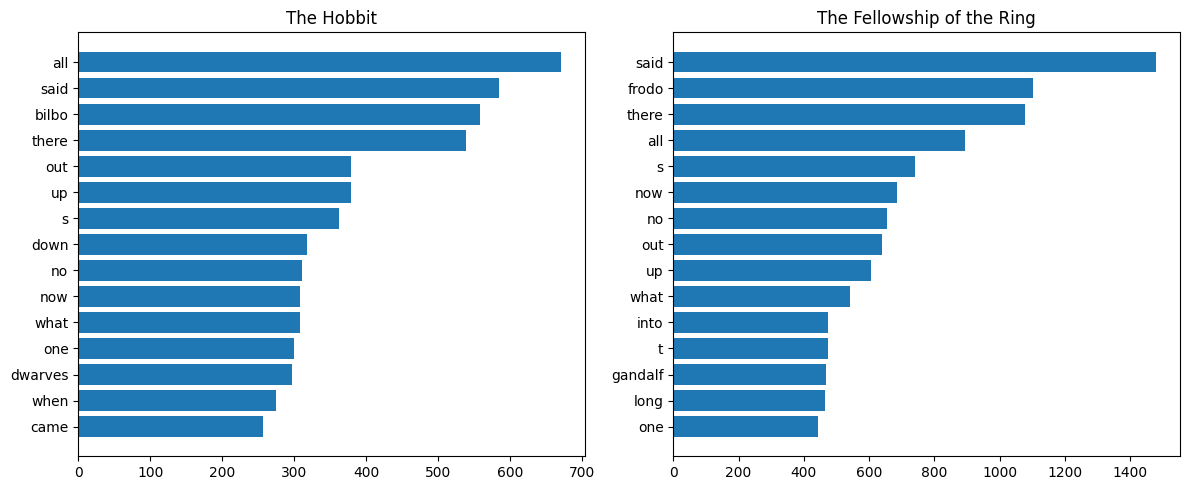

In [3]:
plot_two(hobbit, fellowship, "The Hobbit", "The Fellowship of the Ring")

The two Tolkien books have some similar frequently used words. But many of the differences come from different characters and events in each story.

## 2. Compare word frequencies between works of two authors

J.R.R. Tolkien's *The Hobbit* vs. F.C. Adams's *Manuel Pereira*.

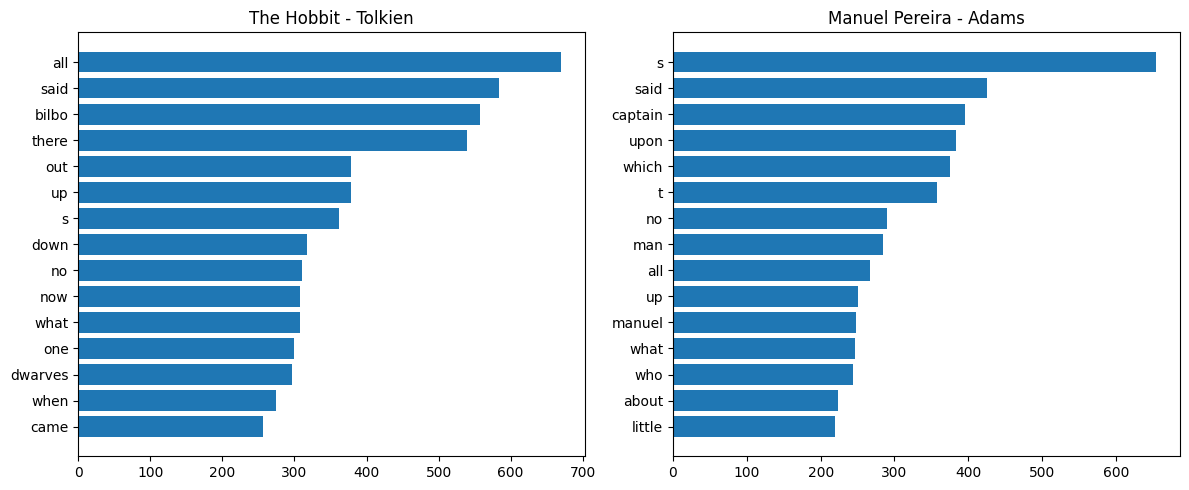

In [4]:
plot_two(hobbit, adams, "The Hobbit - Tolkien", "Manuel Pereira - Adams")

The two authors show different common vocabulary. Some of this is likely caused by the different subjects and settings of the books.

## 3. Are there words preferred by one author but used less frequently by another?

To compare books of different lengths, the code below compares each word by its frequency per 10,000 words.

In [5]:
differences = []
for word in set(hobbit) | set(adams):
    if hobbit[word] + adams[word] >= 20:
        hobbit_rate = hobbit[word] / hobbit_total * 10000
        adams_rate = adams[word] / adams_total * 10000
        differences.append((word, hobbit_rate - adams_rate))

print("Words more common in Tolkien:")
for word, diff in sorted(differences, key=lambda x: x[1], reverse=True)[:10]:
    print(word, round(diff, 2))

print()
print("Words more common in Adams:")
for word, diff in sorted(differences, key=lambda x: x[1])[:10]:
    print(word, round(-diff, 2))


Words more common in Tolkien:
bilbo 103.66
all 72.59
there 63.6
dwarves 55.17
thorin 46.81
down 41.6
out 38.93
gandalf 34.74
came 34.15
back 33.07

Words more common in Adams:
captain 75.08
upon 62.53
s 59.82
manuel 48.19
man 47.94
which 39.42
law 38.08
carolina 32.06
charleston 28.76
south 28.73


Yes. The output shows words that occur proportionally more often in one author's book than the other. These differences may represent author preference, but the topic and characters of each book also affect word choice.